In [1]:
import kagglehub

# Autenticación con Kaggle
kagglehub.login()

# Descargar dataset
print("Descargando dataset...")
try:
    path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")
    print(f"✅ Dataset descargado en: {path}")
except Exception as e:
    print(f"❌ Error: {e}")
    raise

Descargando dataset...
Using Colab cache for faster access to the 'garbage-classification-v2' dataset.
✅ Dataset descargado en: /kaggle/input/garbage-classification-v2


In [2]:
try:
    path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")
    print(f"\n¡Dataset descargado correctamente!")
    print(f"Ubicación: {path}")
except Exception as e:
    print(f"\nError al descargar: {e}")
    print("Alternativa: Intentando con otro dataset...")
    try:
        path = kagglehub.dataset_download("mostafaabla/garbage-classification")
        print(f"\n¡Dataset alternativo descargado!")
        print(f"Ubicación: {path}")
    except Exception as e2:
        print(f"\nTambién falló: {e2}")
        raise

Using Colab cache for faster access to the 'garbage-classification-v2' dataset.

¡Dataset descargado correctamente!
Ubicación: /kaggle/input/garbage-classification-v2


----

In [3]:
!pip install "pillow<12.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 52.7 MB/s eta 0:00:00
  Attempting uninstall: pillow
    Found existing installation: pillow 12.2.0
    Uninstalling pillow-12.2.0:
      Successfully uninstalled pillow-12.2.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
rembg 2.0.76 requires pillow<13.0.0,>=12.1.0, but you have pillow 11.3.0 which is incompatible.


In [4]:
!pip install rembg

  Using cached pillow-12.2.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (8.8 kB)
Using cached pillow-12.2.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (7.1 MB)
  Attempting uninstall: pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 5.50.0 requires pillow<12.0,>=8.0, but you have pillow 12.2.0 which is incompatible.


In [5]:
!pip install onnxruntime

In [6]:
from rembg import remove
from PIL import Image
import numpy as np
print("✅ Todo cargado correctamente. ¡Listo para eliminar fondos!")

✅ Todo cargado correctamente. ¡Listo para eliminar fondos!


📷 Imagen de prueba seleccionada aleatoriamente: /kaggle/input/garbage-classification-v2/standardized_256/cardboard/cardboard_1350.jpg
(Total de 36777 imágenes disponibles)


  0%|                                               | 0.00/176M [00:00<?, ?B/s]

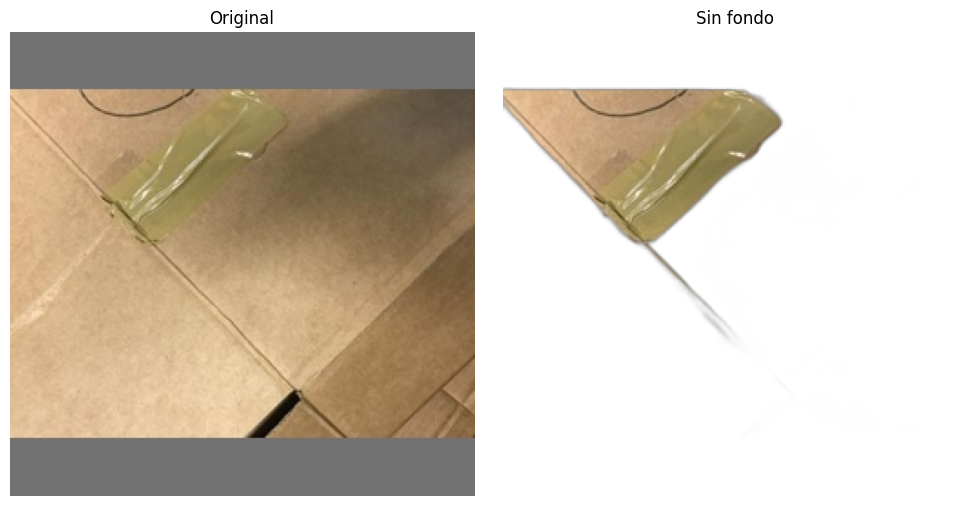

In [7]:
import os
import random
import cv2
import matplotlib.pyplot as plt
from rembg import remove
from PIL import Image

# ------------------------------------------------------------
# 1. Buscar TODAS las imágenes de prueba dentro del dataset
# ------------------------------------------------------------
def find_all_images(base_path, extensions=('.jpg', '.jpeg', '.png', '.bmp')):
    image_paths = []
    for root, dirs, files in os.walk(base_path):
        for file in files:
            if file.lower().endswith(extensions):
                image_paths.append(os.path.join(root, file))
    return image_paths

# Usamos la ruta 'path' obtenida del dataset descargado
if 'path' in locals() or 'path' in globals():
    all_images = find_all_images(path)

    if not all_images:
        print("❌ No se encontró ninguna imagen en el dataset.")
    else:
        # Seleccionar UNA imagen aleatoria
        img_path = random.choice(all_images)
        print(f"📷 Imagen de prueba seleccionada aleatoriamente: {img_path}")
        print(f"(Total de {len(all_images)} imágenes disponibles)")

        # ----------------------------------------------------
        # 2. Cargar imagen con OpenCV y convertir a RGB
        # ----------------------------------------------------
        img_bgr = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # ----------------------------------------------------
        # 3. Eliminar el fondo con rembg
        # ----------------------------------------------------
        pil_img = Image.fromarray(img_rgb)
        pil_no_bg = remove(pil_img)   # Devuelve imagen PIL con fondo transparente

        # ----------------------------------------------------
        # 4. Mostrar ambas imágenes con matplotlib
        # ----------------------------------------------------
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(img_rgb)
        axes[0].set_title("Original")
        axes[0].axis('off')

        axes[1].imshow(pil_no_bg)
        axes[1].set_title("Sin fondo")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

        # Opcional: guardar la imagen sin fondo
        # pil_no_bg.save("imagen_sin_fondo.png")
else:
    print("⚠️ No se encontró la variable 'path' con la ruta del dataset.")

----

📷 Imagen de prueba seleccionada aleatoriamente: /kaggle/input/garbage-classification-v2/standardized_256/plastic/plastic_389.jpg
(Total de 36777 imágenes disponibles)


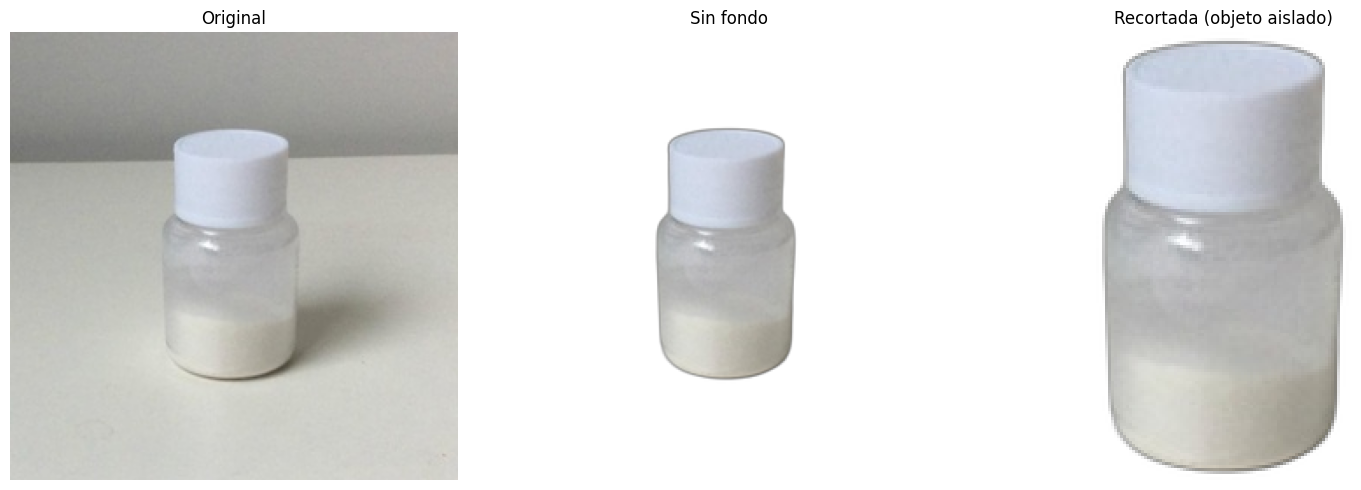

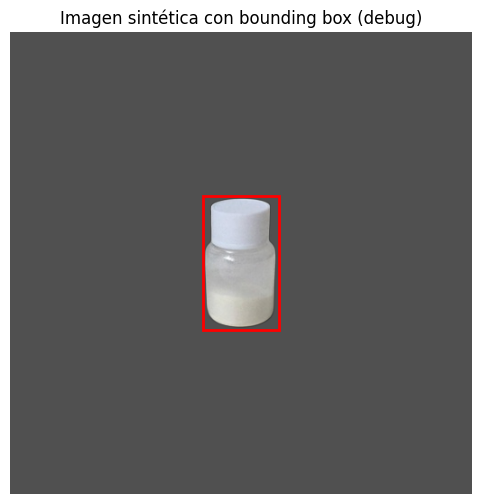

In [13]:
import os
import random
import cv2
import matplotlib.pyplot as plt
from rembg import remove
from PIL import Image
import numpy as np

# ------------------------------------------------------------
# 1. Buscar TODAS las imágenes de prueba dentro del dataset
# ------------------------------------------------------------
def find_all_images(base_path, extensions=('.jpg', '.jpeg', '.png', '.bmp')):
    image_paths = []
    for root, dirs, files in os.walk(base_path):
        for file in files:
            if file.lower().endswith(extensions):
                image_paths.append(os.path.join(root, file))
    return image_paths

# ------------------------------------------------------------
# 2. Función para recortar el objeto sin fondo
# ------------------------------------------------------------
def crop_foreground(pil_img_rgba):
    """
    Recorta la imagen alrededor del objeto (área no transparente)
    y devuelve una nueva imagen PIL (RGBA) con el objeto aislado.
    """
    # Convertir a array numpy para procesar
    img_array = np.array(pil_img_rgba)

    # Obtener el canal alfa (transparencia)
    alpha = img_array[:, :, 3]

    # Encontrar las coordenadas de los píxeles con alpha > 0
    coords = np.argwhere(alpha > 0)
    if coords.size == 0:
        # Si no hay objeto, devolver la imagen original sin cambios
        return pil_img_rgba

    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0)

    # Recortar la imagen al rectángulo del objeto
    cropped = pil_img_rgba.crop((x_min, y_min, x_max + 1, y_max + 1))
    return cropped

# ------------------------------------------------------------
# 3. BLOQUE PRINCIPAL
# ------------------------------------------------------------
# Usamos la ruta 'path' obtenida del dataset descargado
if 'path' in locals() or 'path' in globals():
    all_images = find_all_images(path)

    if not all_images:
        print("❌ No se encontró ninguna imagen en el dataset.")
    else:
        # Seleccionar UNA imagen aleatoria
        img_path = random.choice(all_images)
        print(f"📷 Imagen de prueba seleccionada aleatoriamente: {img_path}")
        print(f"(Total de {len(all_images)} imágenes disponibles)")

        # ----------------------------------------------------
        # Cargar imagen con OpenCV y convertir a RGB
        # ----------------------------------------------------
        img_bgr = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # ----------------------------------------------------
        # Eliminar el fondo con rembg
        # ----------------------------------------------------
        pil_img = Image.fromarray(img_rgb)
        pil_no_bg = remove(pil_img)   # Devuelve imagen PIL con fondo transparente (RGBA)

        # ----------------------------------------------------
        # Recortar la imagen sin fondo para aislar el objeto
        # ----------------------------------------------------
        pil_cropped = crop_foreground(pil_no_bg)

        # ----------------------------------------------------
        # Mostrar las tres imágenes: original, sin fondo, recortada
        # ----------------------------------------------------
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        # Original
        axes[0].imshow(img_rgb)
        axes[0].set_title("Original")
        axes[0].axis('off')

        # Sin fondo (con transparencia visible en matplotlib)
        axes[1].imshow(pil_no_bg)
        axes[1].set_title("Sin fondo")
        axes[1].axis('off')

        # Recortada (objeto aislado)
        axes[2].imshow(pil_cropped)
        axes[2].set_title("Recortada (objeto aislado)")
        axes[2].axis('off')

        plt.tight_layout()
        plt.show()

        # (Opcional) Guardar las imágenes
        # pil_no_bg.save("imagen_sin_fondo.png")
        # pil_cropped.save("objeto_recortado.png")
else:
    print("⚠️ No se encontró la variable 'path' con la ruta del dataset.")


# ------------------------------------------------------------
# 4. CREAR IMAGEN SINTÉTICA CON FONDO GRIS Y BOUNDING BOX
# ------------------------------------------------------------
# Tamaño del lienzo (cuadrado)
CANVAS_SIZE = 512
# Color de fondo (gris medio-oscuro)
BG_COLOR = (80, 80, 80)  # RGB

# 4.1 Crear lienzo gris
canvas = Image.new('RGB', (CANVAS_SIZE, CANVAS_SIZE), BG_COLOR)

# 4.2 Obtener dimensiones del objeto recortado
w, h = pil_cropped.size

# 4.3 Calcular posición para centrar el objeto
x = (CANVAS_SIZE - w) // 2
y = (CANVAS_SIZE - h) // 2

# 4.4 Pegar el objeto sobre el lienzo (usando su canal alfa como máscara)
canvas.paste(pil_cropped, (x, y), pil_cropped)  # tercer argumento = máscara

# 4.5 La bounding box del objeto en el lienzo
bbox = (x, y, x + w, y + h)  # (x_min, y_min, x_max, y_max)

# 4.6 Mostrar la imagen sintética y la bounding box
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.imshow(canvas)

# Dibujar rectángulo de la bounding box (color rojo, grosor 2)
rect = plt.Rectangle((x, y), w, h, linewidth=2, edgecolor='red', facecolor='none')
ax.add_patch(rect)

ax.set_title("Imagen sintética con bounding box (debug)")
ax.axis('off')
plt.show()

# Opcional: guardar la imagen sintética
# canvas.save("imagen_sintetica.png")